# 03 — Validation de la présélection de variables

**Objectif :** vérifier si on peut retirer les variables signalées dans le notebook 02
(`TotalCharges`, `MultipleLines`, `PhoneService`, `gender`) **sans dégrader** le modèle de référence
(régression logistique).

**Méthode :**

1. On entraîne le même modèle dans plusieurs scénarios : toutes les variables, puis sans chaque
   candidate (ou groupe de candidates), puis sans les 4.
2. On compare les scénarios par **validation croisée sur le jeu d'entraînement** (AUC, rappel, précision, F1).
   C'est cette comparaison qui sert à **décider**.
3. On évalue ensuite chaque scénario **une seule fois** sur le jeu de test, uniquement pour confirmer.
   Le jeu de test ne sert pas à choisir, sinon il n'est plus un jeu de test.

In [3]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Permet d'importer le package src depuis le dossier notebooks/
sys.path.append(str(Path.cwd().parent))
from src.data.clean_data import load_data, clean_data

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Paramètres (garder cohérents avec le notebook 02 et src/features/build_features.py)
TEST_SIZE = 0.2
RANDOM_STATE = 42
TOLERANCE_AUC = 0.005      # écart d'AUC considéré comme négligeable
TOLERANCE_RAPPEL = 0.01    # écart de rappel considéré comme négligeable

## 1. Données et séparation entraînement / test

In [4]:
df = clean_data(load_data())
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Entraînement : {X_train.shape} | Test : {X_test.shape}")

Entraînement : (5634, 19) | Test : (1409, 19)


## 2. Scénarios à comparer

Chaque scénario liste les variables **retirées**. On teste les candidates séparément pour savoir
laquelle compte vraiment, puis toutes ensemble.

In [5]:
SCENARIOS = {
    "A_toutes_les_variables": [],
    "B_sans_TotalCharges": ["TotalCharges"],
    "C_sans_gender": ["gender"],
    "D_sans_PhoneService_MultipleLines": ["PhoneService", "MultipleLines"],
    "E_sans_les_4_candidates": ["TotalCharges", "MultipleLines", "PhoneService", "gender"],
}
REFERENCE = "A_toutes_les_variables"

COLONNES_NUMERIQUES = ["tenure", "MonthlyCharges", "TotalCharges"]


def construire_pipeline(exclues):
    """Pipeline de référence : StandardScaler + OneHotEncoder + régression logistique.

    Les colonnes non listées dans le ColumnTransformer sont ignorées, donc il suffit
    de ne pas lister les variables exclues.
    """
    numeriques = [c for c in COLONNES_NUMERIQUES if c not in exclues]
    categorielles = [
        c for c in X_train.columns if c not in COLONNES_NUMERIQUES and c not in exclues
    ]
    preprocesseur = ColumnTransformer([
        ("num", StandardScaler(), numeriques),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorielles),
    ])
    return Pipeline([
        ("preprocessing", preprocesseur),
        # class_weight="balanced" : sans cela, le rappel de la classe minoritaire serait très bas.
        # À aligner avec la configuration utilisée dans src/models/train.py.
        ("modele", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])

## 3. Validation croisée sur le jeu d'entraînement

5 plis répétés 3 fois (15 évaluations par scénario), avec les **mêmes découpages** pour tous les
scénarios, ce qui rend la comparaison équitable.

In [6]:
SCORING = {
    "auc": "roc_auc",
    "rappel": "recall",
    "precision": "precision",
    "f1": "f1",
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

lignes_cv = []
auc_par_pli = {}

for nom, exclues in SCENARIOS.items():
    scores = cross_validate(
        construire_pipeline(exclues), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1
    )
    auc_par_pli[nom] = scores["test_auc"]
    ligne = {"scenario": nom, "n_variables": X_train.shape[1] - len(exclues)}
    for metrique in SCORING:
        ligne[f"{metrique}_moy"] = scores[f"test_{metrique}"].mean()
        ligne[f"{metrique}_std"] = scores[f"test_{metrique}"].std()
    lignes_cv.append(ligne)

resultats_cv = pd.DataFrame(lignes_cv).set_index("scenario")

# Écart d'AUC par rapport à la référence, pli par pli
resultats_cv["ecart_auc_vs_A"] = [
    (auc_par_pli[nom] - auc_par_pli[REFERENCE]).mean() for nom in resultats_cv.index
]
display(resultats_cv.round(4))

,n_variables,auc_moy,auc_std,rappel_moy,rappel_std,precision_moy,precision_std,f1_moy,f1_std,ecart_auc_vs_A
scenario,,,,,,,,,,
A_toutes_les_variables,19,0.8461,0.0116,0.8009,0.0301,0.5185,0.0138,0.6292,0.0153,0.0000
B_sans_TotalCharges,18,0.8449,0.0116,0.7938,0.0293,0.5208,0.0144,0.6286,0.0152,-0.0012
C_sans_gender,18,0.8464,0.0116,0.8025,0.0310,0.5184,0.0138,0.6297,0.0156,0.0003
D_sans_PhoneService_MultipleLines,17,0.8450,0.0115,0.7998,0.0285,0.5170,0.0136,0.6278,0.0142,-0.0011
E_sans_les_4_candidates,15,0.8441,0.0113,0.7980,0.0299,0.5210,0.0141,0.6302,0.0156,-0.0020


## 4. Lecture des résultats

Un scénario est considéré **équivalent** à la référence si son AUC et son rappel moyens ne sont pas
plus bas que ceux de A de plus que les tolérances définies en haut du notebook. Si plusieurs scénarios
sont équivalents, on retient celui qui a **le moins de variables**.

,n_variables,auc_moy,rappel_moy,ecart_auc_vs_A,equivalent_a_A
scenario,,,,,
A_toutes_les_variables,19,0.8461,0.8009,0.0000,True
B_sans_TotalCharges,18,0.8449,0.7938,-0.0012,True
C_sans_gender,18,0.8464,0.8025,0.0003,True
D_sans_PhoneService_MultipleLines,17,0.8450,0.7998,-0.0011,True
E_sans_les_4_candidates,15,0.8441,0.7980,-0.0020,True


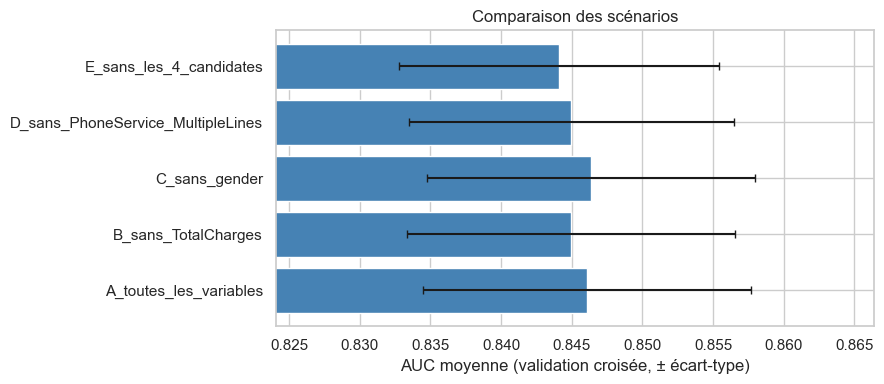

Scénario retenu (le plus simple parmi les équivalents) : E_sans_les_4_candidates


In [9]:
ref = resultats_cv.loc[REFERENCE]
resultats_cv["equivalent_a_A"] = (
    (resultats_cv["auc_moy"] >= ref["auc_moy"] - TOLERANCE_AUC)
    & (resultats_cv["rappel_moy"] >= ref["rappel_moy"] - TOLERANCE_RAPPEL)
)

display(
    resultats_cv[["n_variables", "auc_moy", "rappel_moy", "ecart_auc_vs_A", "equivalent_a_A"]].round(4)
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(
    resultats_cv.index, resultats_cv["auc_moy"], xerr=resultats_cv["auc_std"],
    color="steelblue", capsize=3,
)
ax.set_xlim(resultats_cv["auc_moy"].min() - 0.02, resultats_cv["auc_moy"].max() + 0.02)
ax.set_xlabel("AUC moyenne (validation croisée, ± écart-type)")
ax.set_title("Comparaison des scénarios")
plt.tight_layout()
plt.show()

equivalents = resultats_cv[resultats_cv["equivalent_a_A"]]
retenu = equivalents["n_variables"].idxmin()
print(f"Scénario retenu (le plus simple parmi les équivalents) : {retenu}")

## 5. Confirmation sur le jeu de test

Une seule évaluation par scénario, **sans retour en arrière** pour changer le choix.

In [8]:
lignes_test = []
for nom, exclues in SCENARIOS.items():
    pipe = construire_pipeline(exclues).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    predictions = pipe.predict(X_test)
    lignes_test.append({
        "scenario": nom,
        "n_variables": X_train.shape[1] - len(exclues),
        "auc": roc_auc_score(y_test, proba),
        "rappel": recall_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
    })

resultats_test = pd.DataFrame(lignes_test).set_index("scenario")
display(resultats_test.round(4))

,n_variables,auc,rappel,precision,f1
scenario,,,,,
A_toutes_les_variables,19,0.8415,0.7834,0.5043,0.6136
B_sans_TotalCharges,18,0.8385,0.7727,0.5061,0.6116
C_sans_gender,18,0.8418,0.7834,0.5026,0.6123
D_sans_PhoneService_MultipleLines,17,0.8406,0.7995,0.5059,0.6197
E_sans_les_4_candidates,15,0.8377,0.7834,0.5069,0.6155


## 6. Conclusion et suite

- Si le scénario retenu est **A**, on garde toutes les variables.
- Si c'est un scénario réduit, on retire ces variables **dans le pipeline** (pas seulement dans ce
  notebook). Cela touche :
  1. `src/features/build_features.py` (ne plus lister les variables retirées dans le `ColumnTransformer`) ;
  2. le schéma d'entrée de l'API (`api/main.py`, modèle Pydantic) et les tests associés ;
  3. un réentraînement du modèle et des artefacts (`preprocessor.joblib`, `model.joblib`).
- Vérifier aussi que la conclusion tient avec le modèle final (XGBoost ou autre) : les modèles à base
  d'arbres sont moins sensibles aux variables redondantes que la régression logistique.